In [132]:
# import libraries
import numpy as np
import matplotlib.pyplot as plt # for plots
import matplotlib.colors as colours # for colour bars
from astropy.io import ascii 
from astropy.table import Table, join
from scipy.odr import * 
import pandas as pd

filtered_catalogue_will = ascii.read("../filtered_catalogue_will.csv", 
                                     format='basic', 
                                     delimiter=',', 
                                     guess=False, 
                                     encoding="utf-8") 
#specifying the format encoding="utf-8" specifies this is the way we are formating it, error popped up because of dashes in the csv for Range
filtered_catalogue_will

quantity,cluster_id,preferred_name,NGC,matched_to_harris,ID,Name,RA,DEC,L,B,R_Sun,R_gc,X,Y,Z,NGC_1,ID_1,v_r,v_r_e,v_LSR,sig_v,sig_v_e,c,r_c,r_h,mu_V,rho_0,lg_tc,lg_th,NGC_2,Class,Object,AltName,Mstar,rh,C5,Age,FeH,NGC_3,NGC_4,Name_1,FeH_1,Age_1,Age_err,Method,Figs,Range,HBtype,R_G,M_V,v_e0,log_sigma_0
str8,str8,str8,int64,str4,str8,str6,str11,str11,float64,float64,float64,float64,float64,float64,float64,int64,str8,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,str2,str11,str11,float64,float64,float64,float64,float64,int64,int64,str5,float64,float64,float64,str1,str5,str11,float64,float64,float64,float64,float64
NGC 104,NGC 104,47 Tuc,104,True,NGC 104,47 Tuc,00:24:05.67,-72:04:52.6,305.89,-44.89,4.5,7.4,1.9,-2.6,-3.1,104,NGC 104,-18.0,0.1,-26.7,11.0,0.3,2.07,0.36,3.17,14.38,4.88,7.84,9.55,104,GC,NGC104,47Tuc,6.46,7.1,0.92,12.8,-0.76,104,104,47Tuc,-0.76,11.75,0.25,V,14,11.50–11.75,-0.99,7.4,-9.42,54.8,5.061
NGC 288,NGC 288,NGC 288,288,True,NGC 288,--,00:52:45.24,-26:34:57.4,152.3,-89.38,8.9,12.0,-0.1,0.0,-8.9,288,NGC 288,-45.4,0.2,-51.9,2.9,0.3,0.99,1.35,2.23,20.05,1.78,8.99,9.32,288,GC,NGC288,Melotte3,0.46,9.8,0.05,12.2,-1.32,288,288,--,-1.32,11.5,0.38,H,24,--,0.98,12.0,-6.75,10.9,2.953
NGC 362,NGC 362,NGC 362,362,True,NGC 362,--,01:03:14.26,-70:50:55.6,301.53,-46.25,8.6,9.4,3.1,-5.1,-6.2,362,NGC 362,223.5,0.5,214.0,6.4,0.3,1.76,0.18,0.82,14.8,4.74,7.76,8.93,362,GC,NGC362,Dunlop62,2.5,3.5,0.72,10.0,-1.26,362,362,--,-1.3,10.75,0.25,V,13,10.75–11.00,-0.87,9.4,-8.43,44.4,4.938
NGC 1261,NGC 1261,NGC 1261,1261,True,NGC 1261,--,03:12:16.21,-55:12:58.4,270.54,-52.12,16.3,18.1,0.1,-10.0,-12.9,1261,NGC 1261,68.2,4.6,54.9,--,--,1.16,0.35,0.68,17.73,2.99,8.59,9.12,1261,GC,NGC1261,Caldwell87,3.41,5.5,0.62,10.24,-1.08,1261,1261,--,-1.27,10.75,0.25,V,13,10.75–11.25,-0.71,18.1,-7.8,23.6,3.913
NGC 1851,NGC 1851,NGC 1851,1851,True,NGC 1851,--,05:14:06.76,-40:02:47.6,244.51,-35.03,12.1,16.6,-4.2,-8.9,-6.9,1851,NGC 1851,320.5,0.6,303.8,10.4,0.5,1.86,0.09,0.51,14.25,5.09,7.43,8.82,1851,GC,NGC1851,Dunlop508,5.51,3.05,1.81,7.64,-1.13,1851,1851,--,-1.18,11.0,0.25,V,13,10.75–11.25,-0.32,16.6,-8.33,47.6,5.136
NGC 1904,NGC 1904,M 79,1904,True,NGC 1904,M 79,05:24:11.09,-24:31:29.0,227.23,-29.35,12.9,18.8,-7.7,-8.3,-6.3,1904,NGC 1904,205.8,0.4,189.0,5.3,0.4,1.7,0.16,0.65,16.02,4.08,7.83,8.95,1904,GC,NGC1904,M79,1.45,4.1,0.5,12.0,-1.58,1904,--,--,--,--,--,--,--,--,--,--,--,--,--
NGC 2298,NGC 2298,NGC 2298,2298,True,NGC 2298,--,06:48:59.41,-36:00:19.1,245.63,-16.0,10.8,15.8,-4.3,-9.4,-3.0,2298,NGC 2298,148.9,1.2,132.0,--,--,1.38,0.31,0.98,18.9,2.9,7.91,8.84,2298,GC,NGC2298,Dunlop578,0.85,3.1,0.16,12.4,-1.98,2298,--,--,--,--,--,--,--,--,--,--,--,--,--
NGC 2808,NGC 2808,NGC 2808,2808,True,NGC 2808,--,09:12:03.10,-64:51:48.6,282.19,-11.25,9.6,11.1,2.0,-9.2,-1.9,2808,NGC 2808,101.6,0.7,89.2,13.4,1.2,1.56,0.25,0.8,15.08,4.66,8.24,9.15,2808,GC,NGC2808,Dunlop265,12.3,3.8,3.24,11.2,-1.18,2808,2808,--,-1.18,11.0,0.38,V,13,11.00–11.25,-0.49,11.1,-9.39,62.4,5.07
NGC 3201,NGC 3201,NGC 3201,3201,True,NGC 3201,--,10:17:36.82,-46:24:44.9,277.23,8.64,4.9,8.8,0.6,-4.8,0.7,3201,NGC 3201,494.0,0.2,482.9,5.0,0.2,1.29,1.3,3.1,19.0,2.71,8.61,9.27,3201,GC,NGC3201,Dunlop445,1.1,7.5,0.15,11.1,-1.51,3201,3201,--,-1.51,11.5,0.38,A,12-30,11.25–11.75,0.08,8.8,-7.45,17.9,3.599


In [133]:
filtered_FeH = filtered_catalogue_will['FeH']
filtered_FeH # to check if the correct column was read in
filtered_Age = filtered_catalogue_will['Age']
filtered_Age # to check if the correct column was read in
filtered_R_G = filtered_catalogue_will['R_G']
filtered_R_G # to check if the correct column was read in

7.4
12.0
9.4
18.1
16.6
--
--
11.1
8.8
21.4
--


In [134]:
print(f"Total number of crosses: {len(FeHvsAge.get_offsets())}")

Total number of crosses: 63


In [135]:
# Create a exponential curve to divide the accreted and in-situ GC's
def model(x, a, b, c):
    return c - a * np.exp(b * x)
a, b, c = 11.6, 1.22, 14.6

In [136]:
x = np.asarray(filtered_FeH, dtype=float)
y = np.asarray(filtered_Age, dtype=float)
rgc = np.asarray(filtered_R_G, dtype=float)

redcutoff = model(x, a, b, c)        # age the red line gives at each point's [Fe/H]
in_range = (x >= -2.4) & (x <= -0.48)  # so it doesn't go outside the dataset
below = (y < redcutoff) & in_range # things below the red line and between -2.4 and -0.48

below_mask = pd.DataFrame({ 
    'FeH': x[below], 
    'Age': y[below],
    'R_gc': rgc[below],
    'Line_Age': redcutoff[below],
    'Offset': y[below] - redcutoff[below],   # negative = below the line
}).sort_values('Offset').reset_index(drop=True)

print(f"{below.sum()} of {len(x)} points are below the line")
print(below_mask)

38 of 63 points are below the line
     FeH    Age  R_gc   Line_Age    Offset
0  -1.13   7.64  16.6  11.677600 -4.037600
1  -1.80  11.00  21.4  13.309532 -2.309532
2  -1.51  10.50   3.9  12.761766 -2.261766
3  -1.26  10.00   9.4  12.106206 -2.106206
4  -0.81   8.60  15.8  10.281945 -1.681945
5  -1.51  11.10   8.8  12.761766 -1.661766
6  -1.58  11.60   0.0  12.912235 -1.312235
7  -1.25  10.80  18.9  12.075596 -1.275596
8  -1.98  12.30  17.8  13.563961 -1.263961
9  -1.08  10.24  18.1  11.493785 -1.253785
10 -1.32  11.10  12.8  12.282231 -1.182231
11 -2.27  12.70  10.2  13.872684 -1.172684
12 -1.98  12.40   0.0  13.563961 -1.163961
13 -1.21  10.90  12.9  11.949349 -1.049349
14 -1.34  11.40  12.0  12.338100 -0.938100
15 -1.30  11.30   7.0  12.224982 -0.924982
16 -1.58  12.00   0.0  12.912235 -0.912235
17 -1.73  12.30   0.0  13.194483 -0.894483
18 -1.33  11.50   6.2  12.310336 -0.810336
19 -2.16  13.00  19.4  13.768226 -0.768226
20 -1.76  12.50  11.2  13.244995 -0.744995
21 -1.50  12.00   0

In [137]:
print(below.sum(), "below the line,", (~below).sum(), "others")    # expect 36 below

x = np.asarray(filtered_FeH, dtype=float)
z = np.asarray(filtered_Age, dtype=float)
assert len(x) == len(below), f"{len(x)} plotted points vs {len(below)} in mask"

38 below the line, 25 others


In [138]:
# Names of the points below the line (cluster_id holds names like "NGC 104")
df = filtered_catalogue_will.to_pandas()
df.columns = [str(c).strip() for c in df.columns]
if len(df) == len(below):
    print(', '.join(df.loc[below, 'cluster_id'].astype(str).str.strip()))

NGC 288, NGC 362, NGC 1261, NGC 1851, NGC 1904, NGC 2298, NGC 2808, NGC 3201, NGC 4147, Rup 106, NGC 4590, NGC 4833, NGC 5024, NGC 5053, NGC 5272, NGC 5286, NGC 5466, NGC 5897, NGC 5904, NGC 5986, NGC 6093, NGC 6121, NGC 6101, NGC 6139, NGC 6205, NGC 6254, NGC 6341, NGC 6397, NGC 6535, NGC 6584, NGC 6656, NGC 6715, Terzan 8, NGC 6934, NGC 6981, NGC 7078, NGC 7089, Pal 12


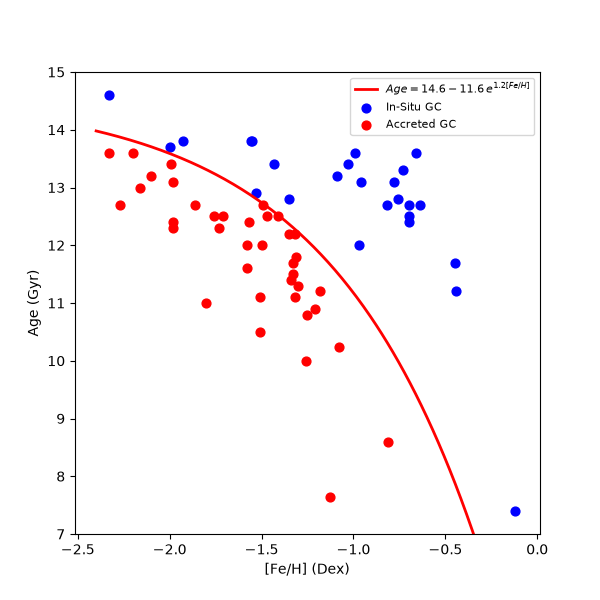

In [139]:
import numpy as np
import matplotlib.pyplot as plt
import mplcursors

# Extract the cluster_id column as text/strings
cluster_ids = np.asarray(filtered_catalogue_will['cluster_id'], dtype=str)

fig, axes = plt.subplots(1, figsize=(6, 6))

def model(x, a, b, c):
    return c - a * np.exp(b * x)

a, b, c = 11.6, 1.22, 14.6
x_fit = np.linspace(-2.4, -0.1, 300)
axes.plot(x_fit, model(x_fit, a, b, c), color='red', lw=2,
          label=f'$Age = {c:.1f} - {a:.1f}\\,e^{{{b:.1f}[Fe/H]}}$')

# 1. Plot In-Situ GC points and store the reference
scatter_other = axes.scatter(
    x[~below], z[~below], 
    color='blue', s=40, label='In-Situ GC'
)

# 2. Plot Accreted GC points and store the reference
scatter_below = axes.scatter(
    x[below], z[below], 
    color='red', s=40, label='Accreted GC'
)

axes.set_xlabel(r'$\mathrm{[Fe/H]}$ ($\mathrm{Dex}$)')
axes.set_ylabel(r'$\mathrm{Age}$ ($\mathrm{Gyr}$)')
axes.set_ylim(7, 15)
axes.legend(fontsize=8)

# --- 3. Add Hover with Cluster IDs & Coordinates ---
cursor = mplcursors.cursor([scatter_other, scatter_below], hover=True)

@cursor.connect("add")
def on_add(sel):
    idx = sel.index
    
    # Match clicked point back to the correct cluster name string
    if sel.artist == scatter_below:
        name = cluster_ids[below][idx]
    else:
        name = cluster_ids[~below][idx]
        
    # Display the cluster name, [Fe/H], and Age on hover
    sel.annotation.set_text(f"Cluster: {name}\n[Fe/H]: {sel.target[0]:.2f}\nAge: {sel.target[1]:.2f} Gyr")
    sel.annotation.get_bbox_patch().set(fc="white", alpha=0.9)

plt.show()

